In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from statsmodels.tsa.stattools import adfuller, kpss
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, mean_absolute_percentage_error

In [2]:
ticker = ["^GSPC", "^HSI", "0386.HK", "0388.HK", "0005.HK"]
df = [yf.download(i, start="2023-01-01", end="2026-09-30",auto_adjust=True, progress=False
                  ).droplevel(['Ticker'], axis=1).reset_index(drop=False).rename_axis(i)
                  for i in ticker]

In [3]:
data = list(range(len(ticker)))
for i in range(len(data)):
    data[i] = df[i].copy()
    data[i]['Return'] = data[i].Close.pct_change()
    data[i]['Target'] = data[i].Return.shift(-1)
    data[i]['TargetClose'] = data[i].Close.shift(-1)
    data[i]['MA5'] = data[i].Close.rolling(5).mean()
    data[i]['MA20'] = data[i].Close.rolling(20).mean()
    data[i]['MA5_ratio'] = data[i].MA5 / data[i].Close -1
    data[i]['MA20_ratio'] = data[i].MA20 / data[i].Close -1
    data[i]['Vol_std_5'] = data[i].Volume.rolling(5).std()
    data[i]['Vol_std_20'] = data[i].Volume.rolling(20).std()
    data[i]['Vol_scaled'] = data[i].Vol_std_5 / data[i].Vol_std_20 -1
    data[i]['Return_std_5'] = data[i].Return.rolling(5).std()
    data[i]['Return_std_20'] = data[i].Return.rolling(20).std()
    data[i]['Return_scaled'] = data[i].Return_std_5 / data[i].Return_std_20 -1
    data[i].dropna(axis=0, inplace=True)

# Functions

In [4]:
def checkstation(dataseries):
    adf_result = adfuller(dataseries, autolag="AIC", result_object=False)
    print("ADF Test Statistic:", adf_result[0])
    print("ADF P-Value:", adf_result[1])
    if adf_result[1] < 0.05:
        print("The series is stationary based on the ADF test (p-value < 0.05).")
    else:
        print("The series is non-stationary based on the ADF test (p-value >= 0.05).")

    kpss_result = kpss(dataseries, regression='c', result_object=False)
    print("\nKPSS Test Statistic:", kpss_result[0])
    print("KPSS P-Value:", kpss_result[1])
    if kpss_result[1] < 0.05:
        print("The series is non-stationary based on the KPSS test (p-value < 0.05).")
    else:
        print("The series is stationary based on the KPSS test (p-value >= 0.05).")

In [5]:
def regression(df, target, features):
    y_reg = df[target]
    X_reg = df[features]

    split_idx = int(len(df)*0.8)
    X_train_r, X_test_r = X_reg.iloc[:split_idx], X_reg.iloc[split_idx:]
    y_train_r, y_test_r = y_reg.iloc[:split_idx], y_reg.iloc[split_idx:]

    reg_model = RandomForestRegressor(n_estimators=200, max_depth=3, random_state=42, n_jobs=-1, min_samples_leaf=30)
    reg_model.fit(X_train_r, y_train_r)
    y_pred_r = reg_model.predict(X_test_r)
    importances = reg_model.feature_importances_

    print("Regression Done")
    print("Parameter Weights:")
    for name, weight in zip(features, importances):
        print(f"{name:<10} : {weight * 100:.2f}%")
    print("\nAccurcy Measure:")
    print(f"MAE      : {mean_absolute_error(y_test_r, y_pred_r):.4f}")
    print(f"RMSE     : {root_mean_squared_error(y_test_r, y_pred_r):.4f}")
    print(f"MAPE     : {mean_absolute_percentage_error(y_test_r, y_pred_r):.4}")
    print(f"R2 Score : {r2_score(y_test_r, y_pred_r):.4f}")
    
    return y_test_r, y_pred_r

In [6]:
def plotresult_regression(df, y_test_r, y_pred_r):
    plt.plot(df.Date[-len(y_test_r):], y_test_r, 'c-', label='Actual Data', linewidth=1)
    plt.plot(df.Date[-len(y_test_r):], y_pred_r, 'r--', label="Predicted Data", linewidth=2, alpha=0.8)

    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(fontsize=11)
    plt.xticks(rotation=45, ha='right')

    plt.tight_layout()
    plt.show()

In [7]:
def result_close(df, y_test_r, y_pred_r):
    pred_date_range = df.Date[-len(y_test_r):]
    pred_data = pd.DataFrame(pred_date_range.copy()) 
    pred_data['Pre_Return'] = y_pred_r 
    pred_data['Close'] = df.Close.copy()
    store_list = [df.Close.iloc[pred_data.index[0]-df.index[0]]]
    for i in range(1, len(pred_data.Pre_Return)):
        store_list.append(store_list[i-1]*(1+pred_data.Pre_Return.iloc[i-1]))
    pred_data['Pre_Close'] = store_list
    
    print(f"MAE      : {mean_absolute_error(pred_data.Close, pred_data.Pre_Close):.4f}")
    print(f"RMSE     : {root_mean_squared_error(pred_data.Close, pred_data.Pre_Close):.4f}")
    print(f"MAPE     : {mean_absolute_percentage_error(pred_data.Close, pred_data.Pre_Close):.4}")
    print(f"R2 Score : {r2_score(pred_data.Close, pred_data.Pre_Close):.4f}")

    return pred_data.Close, pred_data.Pre_Close

# Data Checking

## Check stationary

In [8]:
for i in range(len(ticker)):
    print(f"\n{data[i].index.name}")
    print("Close")
    checkstation(data[i].Close)
    print("\nReturn")
    checkstation(data[i].Return)


^GSPC
Close
ADF Test Statistic: -0.1713569649615397
ADF P-Value: 0.941850781323694
The series is non-stationary based on the ADF test (p-value >= 0.05).

KPSS Test Statistic: 4.717973577963045
KPSS P-Value: 0.01
The series is non-stationary based on the KPSS test (p-value < 0.05).

Return
ADF Test Statistic: -16.93341925942941
ADF P-Value: 9.73831657321435e-30
The series is stationary based on the ADF test (p-value < 0.05).

KPSS Test Statistic: 0.02541428582198203
KPSS P-Value: 0.1
The series is stationary based on the KPSS test (p-value >= 0.05).

^HSI
Close
ADF Test Statistic: -1.143187202328252
ADF P-Value: 0.6975458295139759
The series is non-stationary based on the ADF test (p-value >= 0.05).

KPSS Test Statistic: 3.8099049849912876
KPSS P-Value: 0.01
The series is non-stationary based on the KPSS test (p-value < 0.05).

Return
ADF Test Statistic: -30.400796848350346
ADF P-Value: 0.0
The series is stationary based on the ADF test (p-value < 0.05).

KPSS Test Statistic: 0.1627222

C:\Users\ryanp\AppData\Local\Temp\ipykernel_12788\1456922311.py:10: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(dataseries, regression='c', result_object=False)
C:\Users\ryanp\AppData\Local\Temp\ipykernel_12788\1456922311.py:10: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(dataseries, regression='c', result_object=False)
C:\Users\ryanp\AppData\Local\Temp\ipykernel_12788\1456922311.py:10: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(dataseries, regression='c', result_object=False)
C:\Users\ryanp\AppData\Local\Temp\ipykernel_12788\1456922311.py:10: InterpolationWarning

ADF Test Statistic: -2.4932179688303546
ADF P-Value: 0.11713319878529921
The series is non-stationary based on the ADF test (p-value >= 0.05).

KPSS Test Statistic: 2.3432308398472803
KPSS P-Value: 0.01
The series is non-stationary based on the KPSS test (p-value < 0.05).

Return
ADF Test Statistic: -30.458640577292904
ADF P-Value: 0.0
The series is stationary based on the ADF test (p-value < 0.05).

KPSS Test Statistic: 0.030398071689774684
KPSS P-Value: 0.1
The series is stationary based on the KPSS test (p-value >= 0.05).

0388.HK
Close
ADF Test Statistic: -1.0611614394114175
ADF P-Value: 0.730309265626918
The series is non-stationary based on the ADF test (p-value >= 0.05).

KPSS Test Statistic: 3.5705850142822744
KPSS P-Value: 0.01
The series is non-stationary based on the KPSS test (p-value < 0.05).

Return
ADF Test Statistic: -15.091046032837655
ADF P-Value: 8.192390785834478e-28
The series is stationary based on the ADF test (p-value < 0.05).

KPSS Test Statistic: 0.11999110752

C:\Users\ryanp\AppData\Local\Temp\ipykernel_12788\1456922311.py:10: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(dataseries, regression='c', result_object=False)
C:\Users\ryanp\AppData\Local\Temp\ipykernel_12788\1456922311.py:10: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(dataseries, regression='c', result_object=False)
C:\Users\ryanp\AppData\Local\Temp\ipykernel_12788\1456922311.py:10: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(dataseries, regression='c', result_object=False)
C:\Users\ryanp\AppData\Local\Temp\ipykernel_12788\1456922311.py:10: InterpolationWarning

## Check Correlation

In [9]:
print("Correlations between Close and Features")
for i in range(len(ticker)):
    print(f"\n{data[i].index.name}")
    print(data[i][['MA5','MA20','Vol_std_5']].corrwith(data[i]['TargetClose'], axis=0))

Correlations between Close and Features

^GSPC
Price
MA5          0.997685
MA20         0.993650
Vol_std_5    0.059588
dtype: float64

^HSI
Price
MA5          0.992100
MA20         0.976347
Vol_std_5    0.042192
dtype: float64

0386.HK
Price
MA5          0.972993
MA20         0.918003
Vol_std_5    0.348175
dtype: float64

0388.HK
Price
MA5          0.991388
MA20         0.974565
Vol_std_5   -0.046435
dtype: float64

0005.HK
Price
MA5          0.998484
MA20         0.996150
Vol_std_5   -0.086586
dtype: float64


In [10]:
print("Correlation between Return and Features")
for i in range(len(ticker)):
    print(f"\n{data[i].index.name}")
    print(data[i][['MA5_ratio','MA20_ratio','Vol_scaled', 'Return_scaled']].corrwith(data[i]['Target'], axis=0))

Correlation between Return and Features

^GSPC
Price
MA5_ratio        0.056757
MA20_ratio       0.071347
Vol_scaled      -0.018815
Return_scaled   -0.012016
dtype: float64

^HSI
Price
MA5_ratio        0.014741
MA20_ratio       0.031285
Vol_scaled       0.005708
Return_scaled   -0.019130
dtype: float64

0386.HK
Price
MA5_ratio       -0.003410
MA20_ratio       0.034979
Vol_scaled      -0.017389
Return_scaled   -0.030633
dtype: float64

0388.HK
Price
MA5_ratio       -0.090561
MA20_ratio      -0.015189
Vol_scaled       0.004082
Return_scaled    0.033562
dtype: float64

0005.HK
Price
MA5_ratio        0.003806
MA20_ratio       0.064022
Vol_scaled      -0.057854
Return_scaled   -0.060958
dtype: float64


## Hist

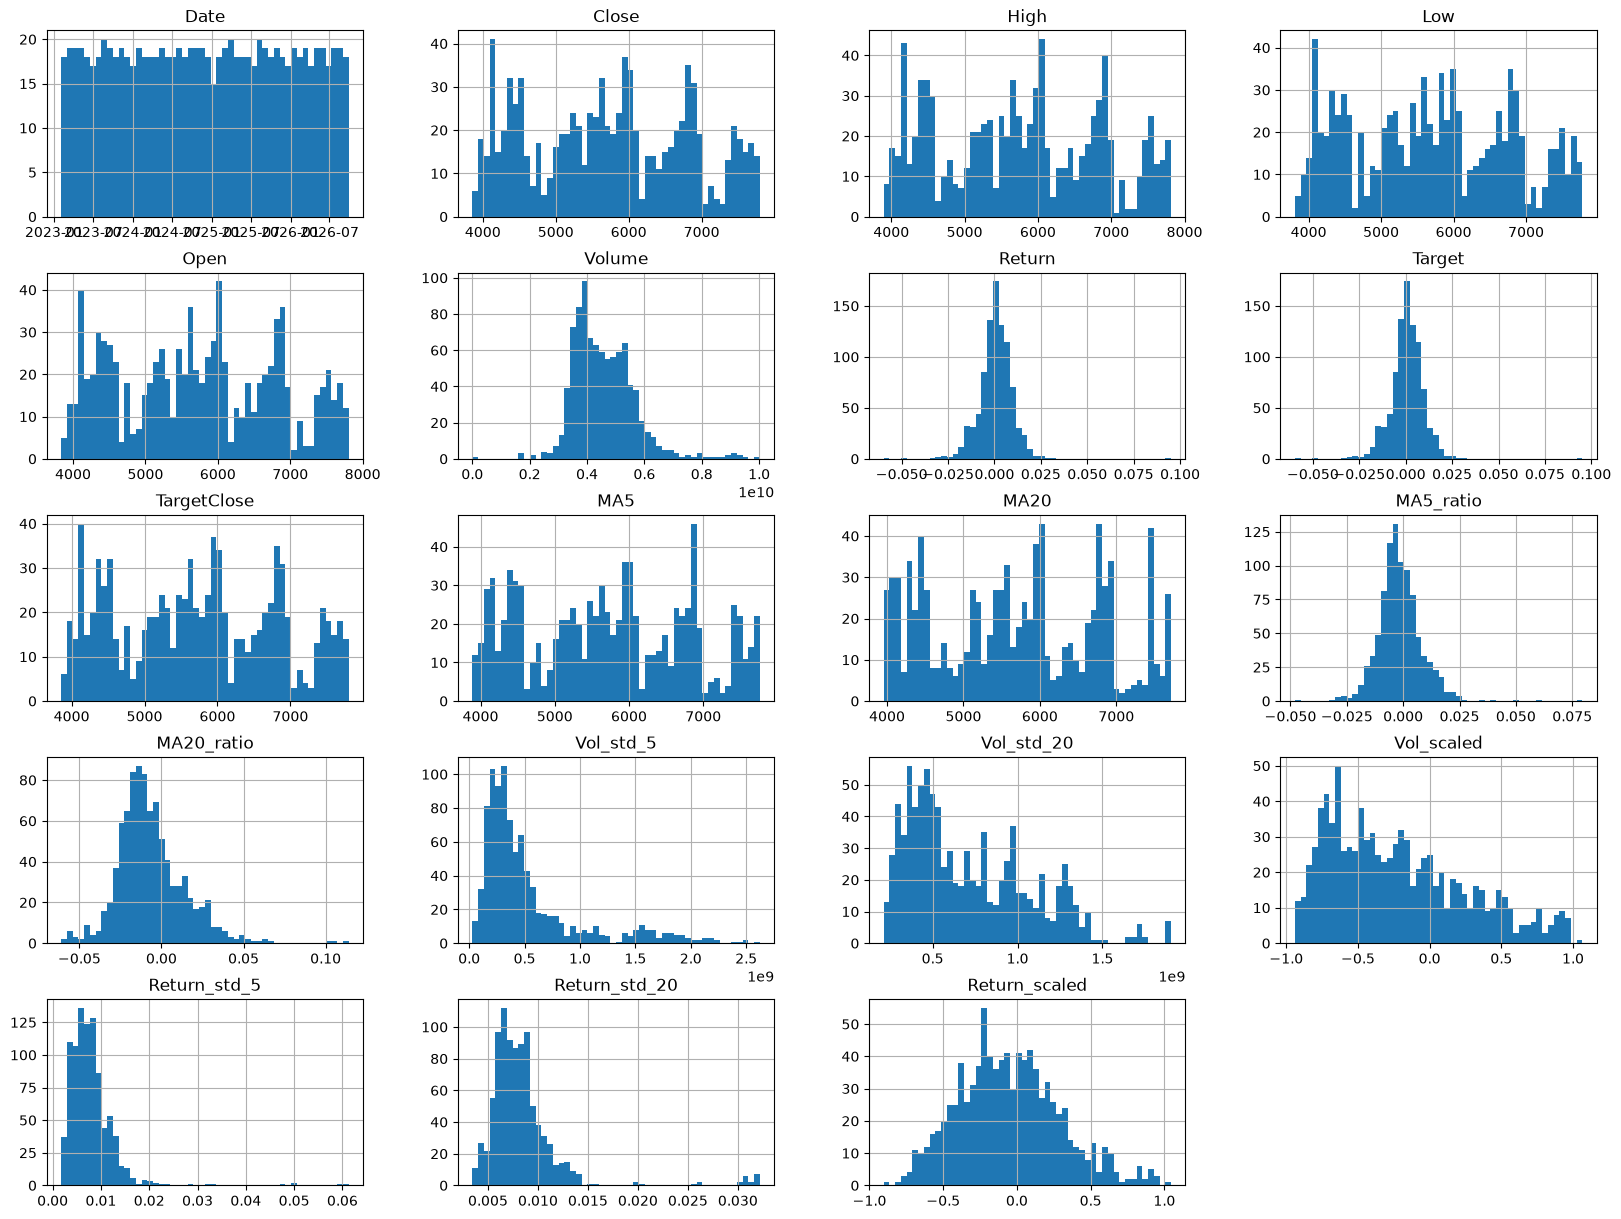

In [11]:
data[0].hist(bins=50, figsize=(20,15)) 
plt.show()

## Stock Daily Close Plot

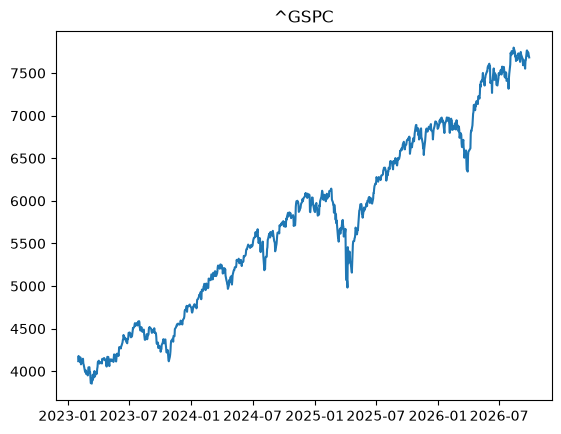

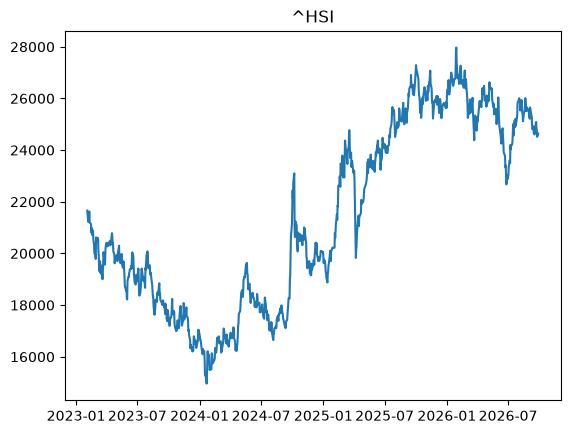

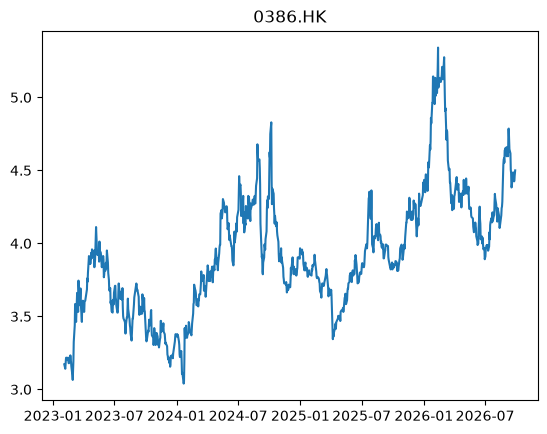

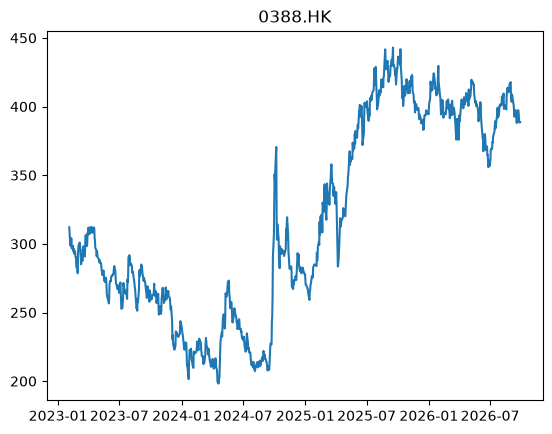

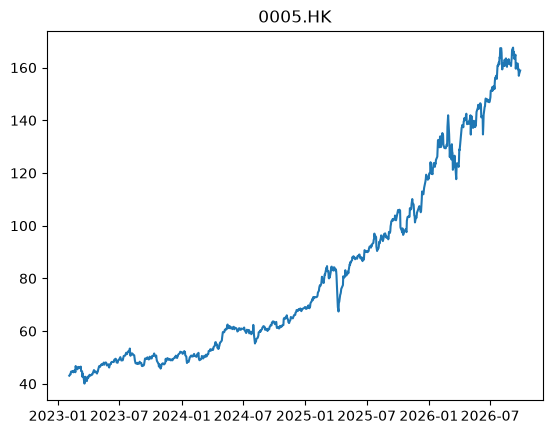

In [12]:
for i in range(len(ticker)):
    plt.figure()
    plt.plot(data[i].Date, data[i].Close)
    plt.title(f"{data[i].index.name}")
    plt.show()

# Stocks Regression


^GSPC
Regression Done
Parameter Weights:
MA5_ratio  : 40.84%
MA20_ratio : 18.03%
Vol_scaled : 24.58%
Return_scaled : 16.56%

Accurcy Measure:
MAE      : 0.0063
RMSE     : 0.0082
MAPE     : 4.086
R2 Score : 0.0268


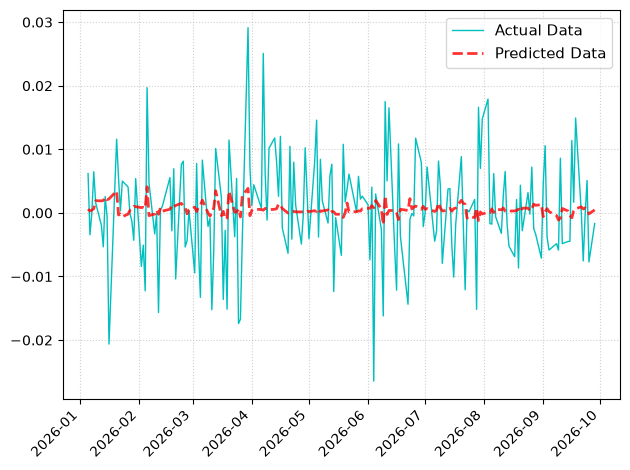

Close Measure:
MAE      : 180.9267
RMSE     : 261.8586
MAPE     : 0.02607
R2 Score : 0.5215


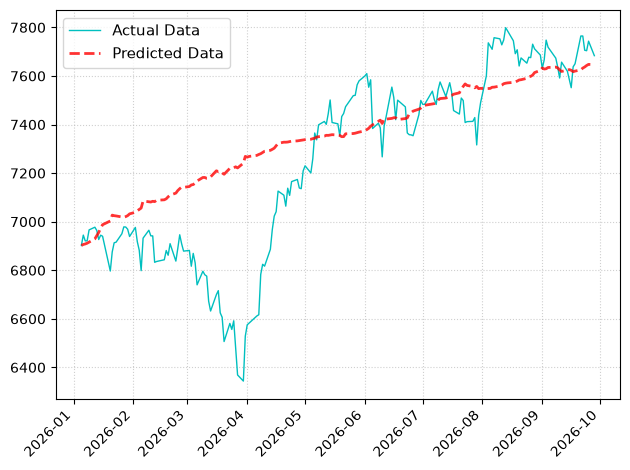


^HSI
Regression Done
Parameter Weights:
MA5_ratio  : 15.88%
MA20_ratio : 37.69%
Vol_scaled : 21.92%
Return_scaled : 24.51%

Accurcy Measure:
MAE      : 0.0095
RMSE     : 0.0117
MAPE     : 1.134
R2 Score : 0.0068


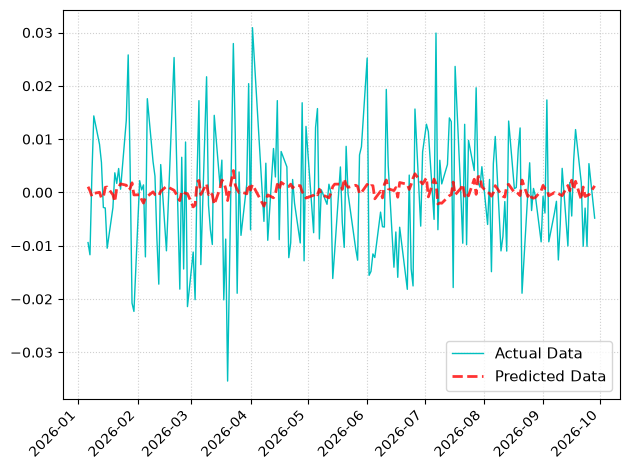

Close Measure:
MAE      : 1907.5445
RMSE     : 2327.9892
MAPE     : 0.07662
R2 Score : -4.6496


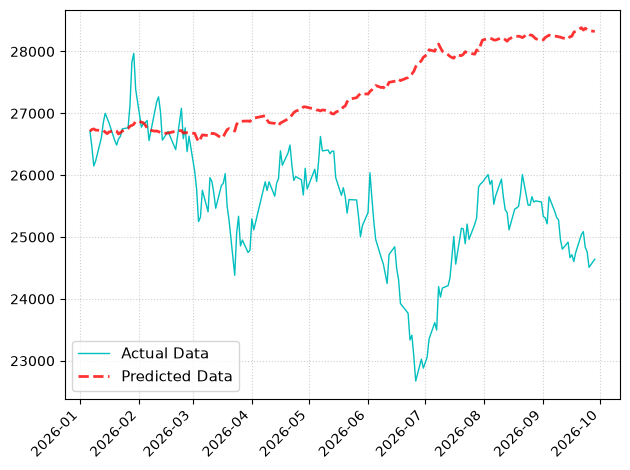


0386.HK
Regression Done
Parameter Weights:
MA5_ratio  : 24.46%
MA20_ratio : 33.28%
Vol_scaled : 20.00%
Return_scaled : 22.26%

Accurcy Measure:
MAE      : 0.0124
RMSE     : 0.0161
MAPE     : 4.509e+11
R2 Score : -0.0071


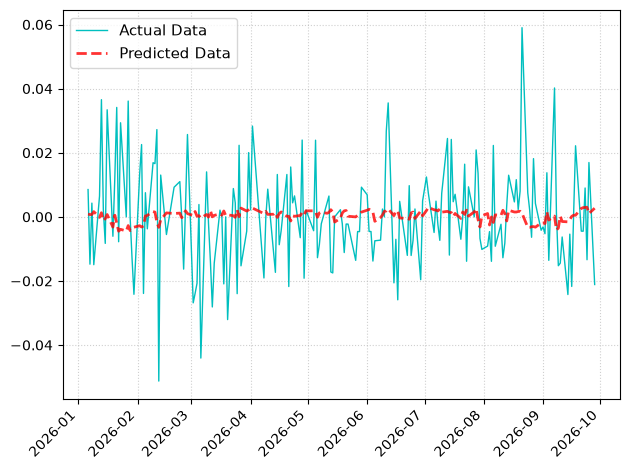

Close Measure:
MAE      : 0.3840
RMSE     : 0.4717
MAPE     : 0.08648
R2 Score : -0.8457


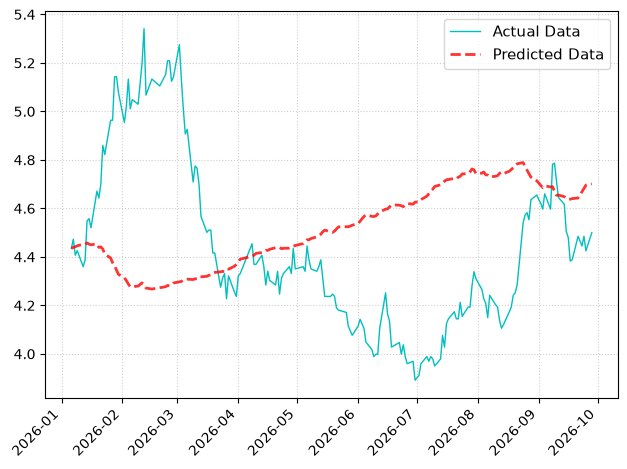


0388.HK
Regression Done
Parameter Weights:
MA5_ratio  : 37.28%
MA20_ratio : 21.92%
Vol_scaled : 16.29%
Return_scaled : 24.51%

Accurcy Measure:
MAE      : 0.0103
RMSE     : 0.0130
MAPE     : 3.268e+10
R2 Score : -0.0504


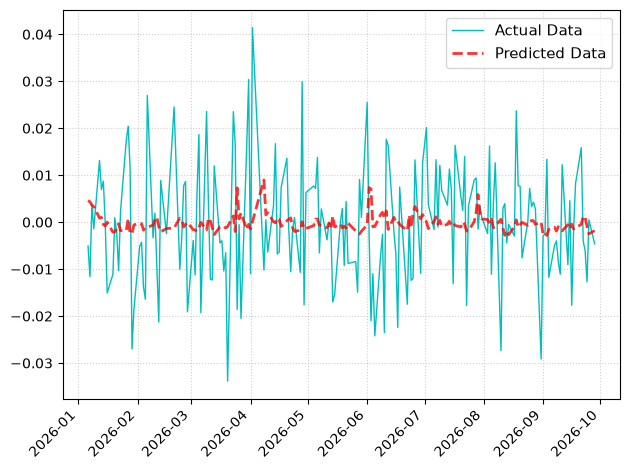

Close Measure:
MAE      : 17.3441
RMSE     : 21.8813
MAPE     : 0.04486
R2 Score : -1.2627


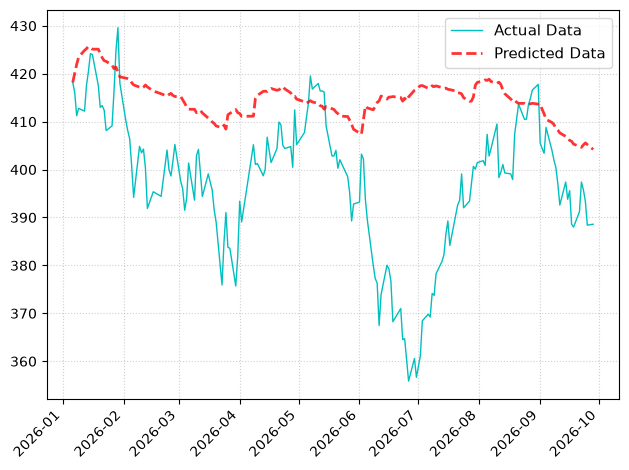


0005.HK
Regression Done
Parameter Weights:
MA5_ratio  : 43.12%
MA20_ratio : 24.24%
Vol_scaled : 17.64%
Return_scaled : 15.00%

Accurcy Measure:
MAE      : 0.0132
RMSE     : 0.0182
MAPE     : 2.195e+11
R2 Score : -0.0523


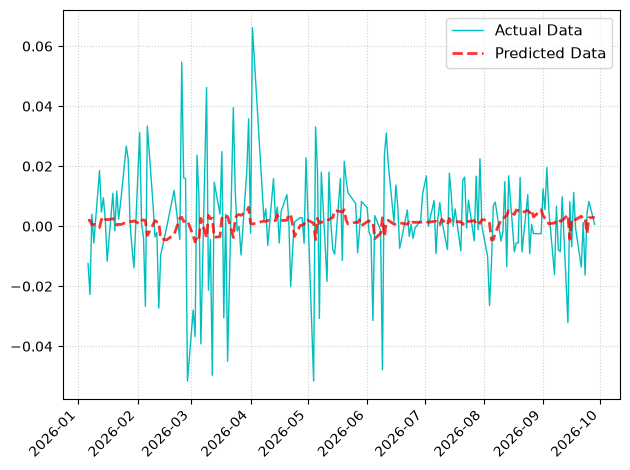

Close Measure:
MAE      : 6.5382
RMSE     : 8.0100
MAPE     : 0.04406
R2 Score : 0.6819


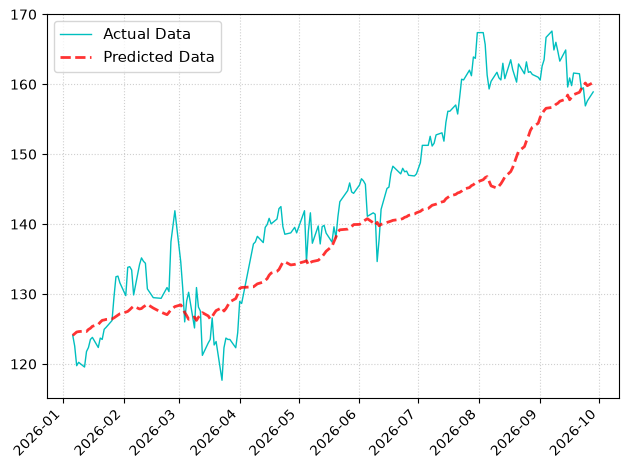

In [13]:
result = []
close_list = []

for i in range(len(ticker)):
    print(f"\n{data[i].index.name}")
    result.append(regression(data[i], 'Target', ['MA5_ratio', 'MA20_ratio', 'Vol_scaled', 'Return_scaled']))
    plotresult_regression(data[i], result[i][0], result[i][1])
    print("Close Measure:")
    close_list.append(result_close(data[i], result[i][0], result[i][1]))
    plotresult_regression(data[i], close_list[i][0], close_list[i][1])

## Output Result as CSV

In [15]:
result_ser_set = [pd.Series([format(mean_absolute_error(close_list[i][0], close_list[i][1]), ".4f"), 
                             format(root_mean_squared_error(close_list[i][0], close_list[i][1]), ".4f"), 
                             format(mean_absolute_percentage_error(close_list[i][0], close_list[i][1]), ".4%"), 
                             format(r2_score(close_list[i][0], close_list[i][1]), ".4f")],
                            index = ["MAE","RMSE","MAPE","R2 Score"],
                            name = ticker[i]) 
                  for i in range(len(ticker))]
result_df = pd.concat(result_ser_set, axis=1)
result_df.to_csv("randomforestresult.csv")

# Void

## Close Regression

In [ ]:
for i in range(len(ticker)):
    actual_price, predicted_close = regression(data[i], 'TargetClose', ['MA5', 'MA20', 'Vol_std_5'])
    plotresult_regression(data[i], actual_price, predicted_close)

## Stock Classification

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
for i in range(len(ticker)):
    data[i]['Direction'] = (data[i]['Target'] > 0).astype(int)

In [ ]:
def classification(df, features):
    y_cl = df.Direction
    X_cl = df[features]

    split_idx = int(len(df) * 0.8)
    X_train_c, X_test_c = X_cl.iloc[:split_idx], X_cl.iloc[split_idx:]
    y_train_c, y_test_c = y_cl.iloc[:split_idx], y_cl.iloc[split_idx:]

    cl_model = RandomForestClassifier(n_estimators=200, max_depth=3, random_state=42, n_jobs=-1, class_weight="balanced")
    cl_model.fit(X_train_c, y_train_c)

    y_pred_c = cl_model.predict(X_test_c)

    print("Classification Done")
    print(classification_report(y_test_c, y_pred_c, target_names=["Drop (0)", "Rise (1)"]))
    
    return y_test_c, y_pred_c

In [ ]:
def plot_cm(y_test_c, y_pred_c):
    cm = confusion_matrix(y_test_c, y_pred_c)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, cmap="Blues",
        xticklabels=["Predicted Drop (0)", "Predicted Rise (1)"],
        yticklabels=["Actual Drop (0)", "Actual Rise (1)"],
        cbar=False
    )

    plt.title("Random Forest Classification: Confusion Matrix Heatmap")
    plt.ylabel("Actual Market Reality")
    plt.xlabel("Model Trading Decision")
    plt.show()

In [ ]:
result_cl = []
for i in range(len(ticker)):
    print(f"\n{data[i].index.name}")
    result_cl.append(classification(data[i], ['MA5_ratio', 'MA20_ratio', 'Vol_scaled', 'Return_scaled']))
    plot_cm(result_cl[i][0], result_cl[i][1])

## Classification without balanced weight

In [ ]:
def class_no_bw(df, features):
    y_cl = df.Direction
    X_cl = df[features]

    split_idx = int(len(df) * 0.8)
    X_train_c, X_test_c = X_cl.iloc[:split_idx], X_cl.iloc[split_idx:]
    y_train_c, y_test_c = y_cl.iloc[:split_idx], y_cl.iloc[split_idx:]

    cl_model = RandomForestClassifier(n_estimators=200, max_depth=3, random_state=42, n_jobs=-1)
    cl_model.fit(X_train_c, y_train_c)

    y_pred_c = cl_model.predict(X_test_c)

    print("Classification Done")
    print(classification_report(y_test_c, y_pred_c, target_names=["Drop (0)", "Rise (1)"]))
    
    return y_test_c, y_pred_c

In [ ]:
result_nbw = []
for i in range(len(ticker)):
    print(f"\n{data[i].index.name}")
    result_nbw.append(class_no_bw(data[i], ['MA5_ratio', 'MA20_ratio', 'Vol_scaled']))
    plot_cm(result_nbw[i][0], result_nbw[i][1])